# Pressure on a cell

Every cell carries a `pressure`: how hard its surroundings press on it. It is the quantity through which
mechanics can act back on biology, for example to stop a crowded cell from growing.

For a cell $c$ with centre $\mathbf X_c$ in $d$ dimensions it is the virial of the forces from outside,

$$P_c = -\frac{1}{d\,V_c}\sum_{i\in c}\;\sum_{j\notin c}\left(\mathbf x_i - \mathbf X_c\right)\cdot\mathbf F_{ij}$$

with $\mathbf F_{ij}$ the force on element $i$ of the cell due to element $j$ outside it.

**Why this is a pressure.** If the surroundings press on the surface $S$ of the cell with a uniform pressure
$p$, the force on a piece of surface is $-p\,\mathbf n\,dA$, and

$$\sum (\mathbf x - \mathbf X_c)\cdot\mathbf F = -p\oint_S (\mathbf x - \mathbf X_c)\cdot\mathbf n\,dA = -p\,d\,V_c$$

by the divergence theorem, so the formula returns $p$.

- **Sign:** positive when the cell is compressed, negative when neighbours pull it outwards (adhesion).
- **Volume:** $V_c$ is nominal, the number of elements times the volume of one element in a close packing at
  the equilibrium distance: $r_\mathrm{eq}^3/\sqrt2$ in 3D, $\tfrac{\sqrt3}{2}r_\mathrm{eq}^2$ in 2D.
- **What counts:** only forces from elements outside the cell. Forces inside the cell, the motility and the
  thermal noise do not.
- **When:** it is computed from the positions at the end of each call of the solver. It is not a time average.

The data comes from the C++ solver through the `pressure` example:

```bash
E=build/gcc-debug/mechanics/micromechanics/examples/mechanics.micromechanics.pressure
D=mechanics/micromechanics/docs/notebooks/data
for n in 13 55; do $E pair $n > $D/pressure_pair_$n.csv; done
for s in 5.5 5.75 6 6.25 6.5 7; do $E confined $s > $D/pressure_confined_$s.csv; done
```

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})


def load(name):
    file = Path("data") / name
    header = file.read_text().splitlines()[0].lstrip("# ").split()
    params = dict(item.split("=") for item in header)
    params = {key: (value if key == "experiment" else float(value)) for key, value in params.items()}
    return params, np.genfromtxt(file, delimiter=",", names=True, skip_header=1)

## Two cells at a fixed distance

Two cells in 3D are placed at a series of centre distances and nothing is allowed to move. This shows what
the pressure reads in the simplest situation.

- Far apart, beyond the cutoff: zero.
- In reach but not touching: the elements attract across the gap, the cell is pulled outwards, the pressure
  is **negative**.
- Overlapping: repulsion wins and the pressure is **positive** and rises steeply.

Where the curve crosses zero the cells neither push nor pull on balance.

Pushed even closer, the elements of one cell end up beyond the centre of the other and push it outwards
from the inside. The formula then returns large negative values that no longer mean tension. That part of
the curve is dotted.

 13 elements: in reach below a centre distance of 3.90, strongest pull -0.145, sign change near 2.35, highest pressure 4.0, cells pushed through each other below 1.45
 55 elements: in reach below a centre distance of 5.30, strongest pull -0.200, sign change near 3.75, highest pressure 3.8, cells pushed through each other below 2.85


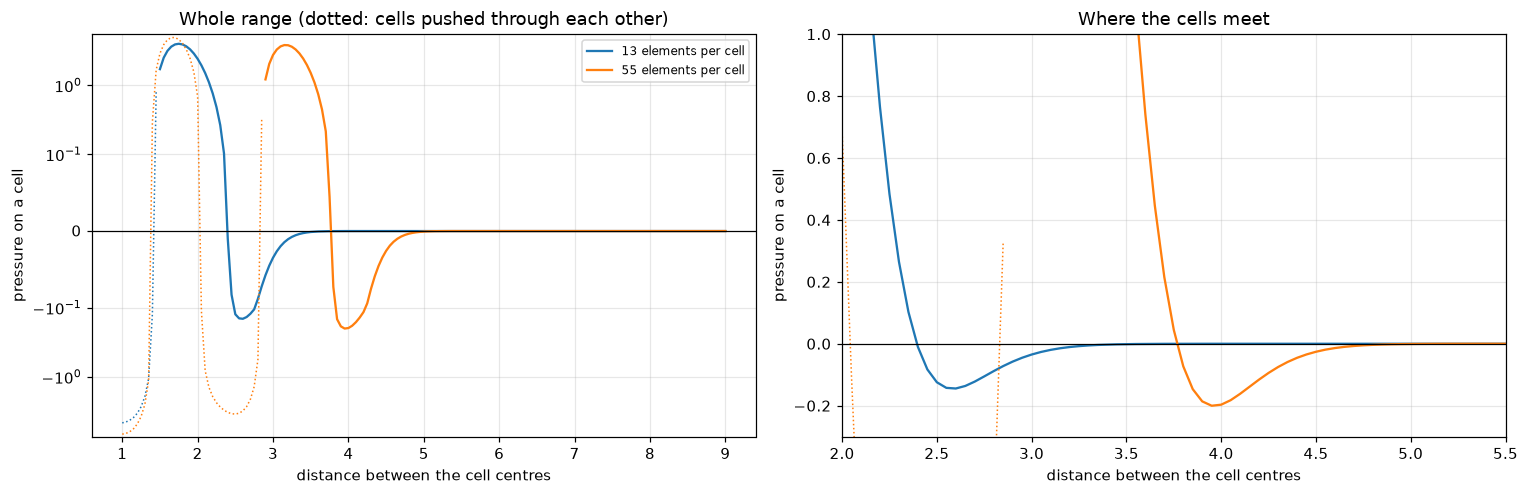

In [2]:
fig, (ax_full, ax_zoom) = plt.subplots(1, 2, figsize=(14, 4.6))

for elements in (13, 55):
    params, table = load(f"pressure_pair_{elements}.csv")
    distance, pressure = table["distance"], table["pressure"]

    in_reach = np.nonzero(pressure)[0]
    sign_changes = np.nonzero(np.diff(np.sign(pressure[in_reach])))[0]
    # coming from far away: first attraction, then (last sign change) compression,
    # and, once the cells are pushed through each other, a second sign change
    balance = distance[in_reach][sign_changes[-1]]
    through = distance[in_reach][sign_changes[-2] + 1]
    valid = distance > through

    for ax in (ax_full, ax_zoom):
        line, = ax.plot(distance[valid], pressure[valid], label=f"{elements} elements per cell")
        ax.plot(distance[~valid], pressure[~valid], color=line.get_color(), linestyle=":", linewidth=1)

    # zero beyond reach, attraction before repulsion as the cells approach
    assert np.all(pressure[in_reach[-1] + 1:] == 0)
    assert pressure[in_reach[-1]] < 0, "the first contact is attractive"
    assert pressure[valid].max() > 1, "overlapping cells are strongly compressed"

    print(f"{elements:>3} elements: in reach below a centre distance of {distance[in_reach[-1]]:.2f}, strongest pull "
          f"{pressure[valid].min():+.3f}, sign change near {balance:.2f}, highest pressure {pressure[valid].max():.1f}, "
          f"cells pushed through each other below {through:.2f}")

for ax in (ax_full, ax_zoom):
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set(xlabel="distance between the cell centres", ylabel="pressure on a cell")
ax_full.set(yscale="symlog", title="Whole range (dotted: cells pushed through each other)")
ax_full.set_yscale("symlog", linthresh=0.1)
ax_full.legend(fontsize=8)
ax_zoom.set(xlim=(2.0, 5.5), ylim=(-0.3, 1.0), title="Where the cells meet")
fig.tight_layout()

## Squeezed cells

Nineteen cells in 2D sit on a hexagonal layout: one in the middle, a ring of six around it and an outer ring
of twelve. The outer ring is fixed in place and acts as a wall. The seven inner cells relax.

The `spacing` between neighbouring cell centres sets how much room the cells have. Each cell is a hexagonal
disc of 37 elements, created 5.2 to 6 wide and somewhat smaller once relaxed. A small spacing squeezes the
cells; a large one holds them apart while they still adhere.

spacing  5.5: mean pressure of the 7 inner cells +2.9983 (from +2.9108 to +3.2252)
spacing 5.75: mean pressure of the 7 inner cells +0.8811 (from +0.8347 to +0.9413)
spacing    6: mean pressure of the 7 inner cells +0.4421 (from +0.3511 to +0.9884)
spacing 6.25: mean pressure of the 7 inner cells -0.2662 (from -0.3733 to -0.1396)
spacing  6.5: mean pressure of the 7 inner cells -0.2808 (from -0.3269 to -0.1410)
spacing    7: mean pressure of the 7 inner cells -0.1993 (from -0.1998 to -0.1992)


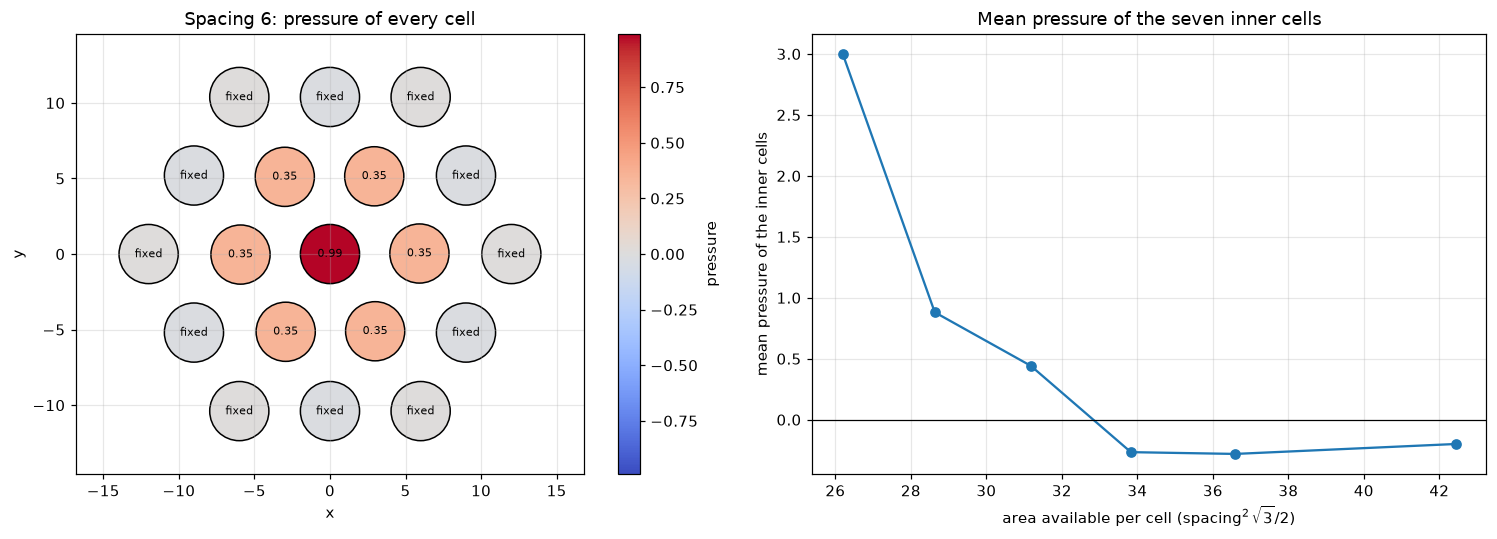

In [3]:
spacings = ["5.5", "5.75", "6", "6.25", "6.5", "7"]
fig, (ax_map, ax_curve) = plt.subplots(1, 2, figsize=(14, 5))

inner_pressure = []
for spacing in spacings:
    params, table = load(f"pressure_confined_{spacing}.csv")
    inner = table["ring"] < 2
    inner_pressure.append(table["pressure"][inner].mean())
    # the inner cells have come to rest
    assert table["speed"][inner].max() < 0.02, f"spacing {spacing}: cells still moving at {table['speed'][inner].max():.3f}"
    print(f"spacing {spacing:>4}: mean pressure of the 7 inner cells {inner_pressure[-1]:+.4f} "
          f"(from {table['pressure'][inner].min():+.4f} to {table['pressure'][inner].max():+.4f})")

params, table = load("pressure_confined_6.csv")
limit = np.abs(table["pressure"]).max()
points = ax_map.scatter(table["x"], table["y"], c=table["pressure"], s=1500, cmap="coolwarm", vmin=-limit, vmax=limit, edgecolors="black")
for row in table:
    ax_map.annotate("fixed" if row["ring"] == 2 else f"{row['pressure']:.2f}", (row["x"], row["y"]), ha="center", va="center", fontsize=7)
fig.colorbar(points, ax=ax_map, label="pressure")
ax_map.set(aspect="equal", xlabel="x", ylabel="y", title="Spacing 6: pressure of every cell")
ax_map.margins(0.2)

area = np.array([float(s) for s in spacings]) ** 2 * np.sqrt(3) / 2
ax_curve.plot(area, inner_pressure, "o-")
ax_curve.axhline(0, color="black", linewidth=0.8)
ax_curve.set(xlabel="area available per cell (spacing$^2\\,\\sqrt{3}/2$)", ylabel="mean pressure of the inner cells",
             title="Mean pressure of the seven inner cells")
fig.tight_layout()

# under compression the pressure falls steadily as the cells get more room, and changes sign
compressed = [p for p in inner_pressure if p > 0]
assert len(compressed) >= 3 and inner_pressure[: len(compressed)] == compressed
assert all(a > b for a, b in zip(compressed, compressed[1:])), "the pressure must fall as squeezed cells get more room"
assert all(p < 0 for p in inner_pressure[len(compressed):]), "cells held apart are under tension"

## Reading the result

- **The pressure has the sign one expects**: positive under compression, negative when cells are held apart
  but still adhere, zero for a cell that touches nothing.
- **Under compression it rises steeply and steadily as the cells get less room**, which is what a signal for
  contact inhibition of growth needs.
- **Under tension it is not monotonic.** As the cells are held further apart the pull first grows and then
  fades, because the attraction between elements has a finite range. At a spacing of 7.5 (not shown) the
  symmetric arrangement no longer holds: the inner cells drift to one side of the ring and were still moving
  at the end of the run.
- **The middle cell reads more than the ring around it** at the same spacing (0.99 against 0.35 at a spacing
  of 6): it is surrounded by six cells that can give way and press back, the ring cells partly by fixed ones.
  The pressure is a property of each cell's own surroundings, not one value for the tissue.
- **Units** are those of the potential: energy per volume, with the well depth and the equilibrium distance
  as units of energy and length.

### Caveats

- **It is the pressure from outside only.** The forces between the elements of the cell itself are left out, so
  this is not the full mechanical stress inside the cell.
- **It assumes the neighbours are outside the cell.** If two cells are pushed through each other, the value
  has no meaning (the dotted part of the first figure). That needs forces far beyond what holds cells apart
  in a normal run, but nothing in the code forbids it.
- **A cell of one element always reads zero**: the element sits on the centre of its cell and has no lever arm.
- **The volume is nominal.** A compressed cell does not get a smaller $V_c$, so at strong compression the value
  is lower than a pressure based on the actual volume would be.
- **It is one number per cell.** A cell pressed from two sides and pulled from two others can read zero.
  Shear and the direction of the load are not captured.
- **It is instantaneous.** With thermal noise it fluctuates from step to step; average it over time before
  using it as a signal.
- **Fixed cells still report a pressure**, computed the same way, but they do not respond to it.